# Dataset Overview

In [1]:
import hashlib
import io
import os
import random
from collections import Counter
from pathlib import Path

REPO_ROOT = Path.cwd().parent
os.environ["HF_HOME"] = str(REPO_ROOT / "data" / "datasets")
os.environ["HF_HUB_OFFLINE"] = "1"

import datasets
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

datasets.logging.set_verbosity_error()
random.seed(0)

SPLIT_NAMES = ["train", "validation", "test"]
SOURCE_NAMES = ["real", "sd21", "sdxl", "sd3", "dalle3", "midjourney"]


def count_table(row_values, column_values):
    table = pd.crosstab(row_values, column_values)
    table.index.name = None
    table.columns.name = None
    return table


dataset =datasets.load_dataset("Rajarshi-Roy-research/Defactify_Image_Dataset")
dataset

DatasetDict({
    validation: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 9000
    })
    train: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 42000
    })
    test: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 45000
    })
})

## Label distribution per split

In [2]:
source_counts = {}
for split_name in SPLIT_NAMES:
    counts = Counter(dataset[split_name]["Label_B"])
    source_counts[split_name] = [counts[label] for label in range(len(SOURCE_NAMES))]

source_table = pd.DataFrame(source_counts, index=SOURCE_NAMES)
source_table

,train,validation,test
real,7000,1500,7500
sd21,7000,1500,7500
sdxl,7000,1500,7500
sd3,7000,1500,7500
dalle3,7000,1500,7500
midjourney,7000,1500,7500


In [3]:
binary_counts = {}
for split_name in SPLIT_NAMES:
    counts = Counter(dataset[split_name]["Label_A"])
    binary_counts[split_name] = [counts[0], counts[1]]

binary_table = pd.DataFrame(binary_counts, index=["real", "ai"])
binary_table

,train,validation,test
real,7000,1500,7500
ai,35000,7500,37500


## Image properties per source

In [4]:
SAMPLES_PER_SOURCE = 200

raw_train = dataset["train"].cast_column("Image", datasets.Image(decode=False))
train_labels = list(dataset["train"]["Label_B"])

summary_rows = []
for label, source_name in enumerate(SOURCE_NAMES):
    source_indices = []
    for index, image_label in enumerate(train_labels):
        if image_label == label:
            source_indices.append(index)

    formats = Counter()
    sizes = Counter()
    kilobytes = []
    for index in random.sample(source_indices, SAMPLES_PER_SOURCE):
        image_bytes = raw_train[index]["Image"]["bytes"]
        image = Image.open(io.BytesIO(image_bytes))
        formats[image.format] += 1
        sizes[f"{image.width}x{image.height}"] += 1
        kilobytes.append(len(image_bytes) / 1000)

    most_common_size = sizes.most_common(1)[0][0]
    summary_rows.append(
        {
            "source": source_name,
            "formats": ", ".join(formats),
            "distinct sizes": len(sizes),
            "most common size": most_common_size,
            "average kilobytes": round(sum(kilobytes) / len(kilobytes)),
        }
    )

pd.DataFrame(summary_rows)

,source,formats,distinct sizes,most common size,average kilobytes
0,real,JPEG,74,640x480,53
1,sd21,JPEG,1,768x768,90
2,sdxl,JPEG,1,1024x1024,117
3,sd3,JPEG,1,1024x1024,143
4,dalle3,JPEG,2,270x270,18
5,midjourney,JPEG,1,436x436,25


## JPEG settings, metadata and duplicates

In [5]:
image_records = []
for split_name in SPLIT_NAMES:
    raw_split = dataset[split_name].cast_column("Image", datasets.Image(decode=False))
    for index, row in enumerate(raw_split):
        image_bytes = row["Image"]["bytes"]
        image = Image.open(io.BytesIO(image_bytes))
        luminance_table = image.quantization[0]
        image_records.append(
            {
                "split": split_name,
                "index": index,
                "source": SOURCE_NAMES[row["Label_B"]],
                "caption": row["Caption"],
                "quantization": round(sum(luminance_table) / len(luminance_table), 1),
                "comment": image.info.get("comment"),
                "hash": hashlib.md5(image_bytes).hexdigest(),
            }
        )

image_records = pd.DataFrame(image_records)
image_records.head()

,split,index,source,caption,quantization,comment,hash
0,train,0,real,Two tall giraffe standing next to each other o...,29.0,None,7d483e695078d789430c0550343793c6
1,train,1,sd21,Two tall giraffe standing next to each other o...,29.0,None,76431d90c4081f9998f3c2a00bc8bb77
2,train,2,sdxl,Two tall giraffe standing next to each other o...,29.0,None,25bbde9c922177fc3ac1365c6a40e778
3,train,3,sd3,Two tall giraffe standing next to each other o...,29.0,None,c036938545abf8455f51a6e842bcbf10
4,train,4,dalle3,Two tall giraffe standing next to each other o...,29.0,None,6514523464cabe72ed322ed449c387ef


In [6]:
count_table(image_records["source"], image_records["quantization"])

,29.0
dalle3,16000
midjourney,16000
real,16000
sd21,16000
sd3,16000
sdxl,16000


In [7]:
images_with_comment = image_records[image_records["comment"].notna()]
print(f"images with a JPEG comment: {len(images_with_comment)}")
print(Counter(images_with_comment["comment"]).most_common(5))
count_table(images_with_comment["source"], images_with_comment["split"])

images with a JPEG comment: 549
[(b'AppleMark\n', 428), (b'File written by Adobe Photoshop\xa8 4.0', 26), (b'*', 8), (b'CREATOR: gd-jpeg v1.0 (using IJG JPEG v62), quality = 90\n', 8), (b'LEAD Technologies Inc. V1.01', 7)]


,train,validation
real,460,89


In [8]:
hash_counts = Counter(image_records["hash"])
duplicate_hashes = []
for image_hash, count in hash_counts.items():
    if count > 1:
        duplicate_hashes.append(image_hash)

duplicates = image_records[image_records["hash"].isin(duplicate_hashes)]
print(f"groups of identical images: {len(duplicate_hashes)}")
print(f"images in these groups: {len(duplicates)}")
count_table(duplicates["source"], duplicates["split"])

groups of identical images: 19
images in these groups: 71


,test,train,validation
midjourney,15,47,9


split  index                                                                caption
train    737              Large white airplane with blue tail sitting on a runway. 
train   3089                 a close up of a tv with a man wearing s suit and shirt
train  14819                         A baby in a carriage on street next to market.
train  16871   Various people walking on a street in front of a wall advertisement.
train  30101 Closed toilet in a narrow, tiled bathroom, with sink and shower stall.


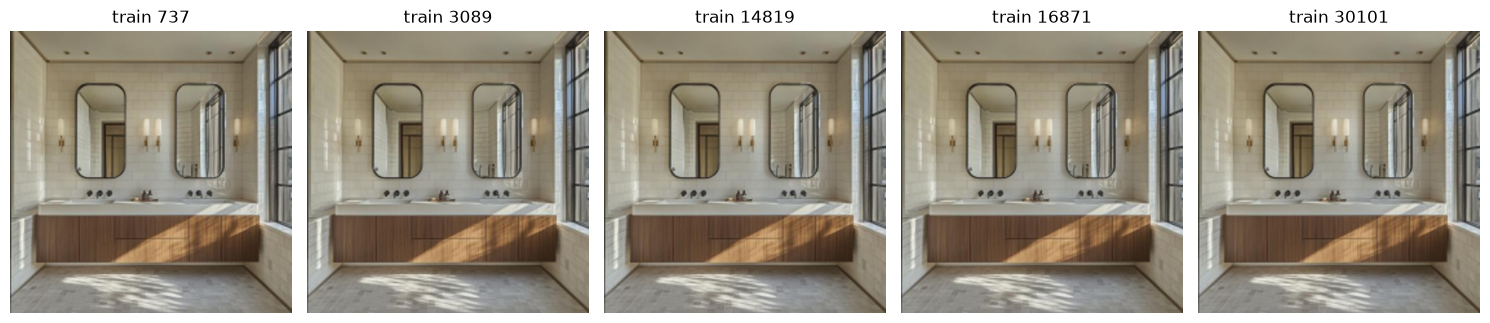

In [9]:
first_group = duplicates[duplicates["hash"] == duplicate_hashes[0]]
print(first_group[["split", "index", "caption"]].to_string(index=False))

figure, axes = plt.subplots(1, len(first_group), figsize=(15, 3.5))
for axis, (split_name, index) in zip(axes, zip(first_group["split"], first_group["index"])):
    axis.imshow(dataset[split_name][int(index)]["Image"])
    axis.set_title(f"{split_name} {index}")
    axis.axis("off")
plt.tight_layout()
plt.show()

## Caption groups

In [10]:
captions_per_split = {}
labels_per_split = {}
for split_name in SPLIT_NAMES:
    captions_per_split[split_name] = list(dataset[split_name]["Caption"])
    labels_per_split[split_name] = list(dataset[split_name]["Label_B"])

group_sizes = {}
for split_name in SPLIT_NAMES:
    images_per_caption = Counter(captions_per_split[split_name])
    group_sizes[split_name] = Counter(images_per_caption.values())

group_size_table = pd.DataFrame(group_sizes).fillna(0).astype(int).sort_index()
group_size_table

,train,validation,test
6,6908,1491,0
12,34,3,0
18,3,1,0
24,1,0,0
30,1,0,1500
36,1,0,0


In [11]:
caption_sets = {}
for split_name in SPLIT_NAMES:
    caption_sets[split_name] = set(captions_per_split[split_name])

all_captions = caption_sets["train"] | caption_sets["validation"] | caption_sets["test"]

captions_in_several_splits = 0
for caption in all_captions:
    number_of_splits = 0
    for split_name in SPLIT_NAMES:
        if caption in caption_sets[split_name]:
            number_of_splits += 1
    if number_of_splits > 1:
        captions_in_several_splits += 1

print(f"unique captions: {len(all_captions)}")
print(f"captions in more than one split: {captions_in_several_splits}")

unique captions: 9884
captions in more than one split: 55


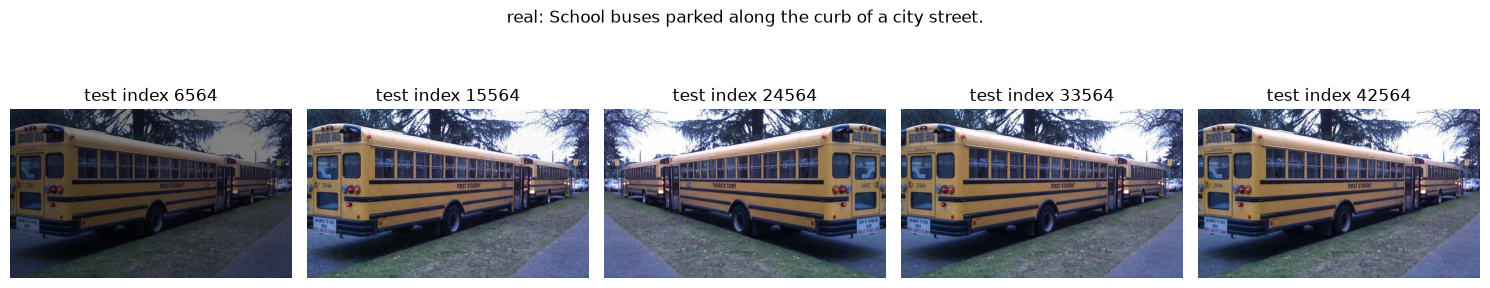

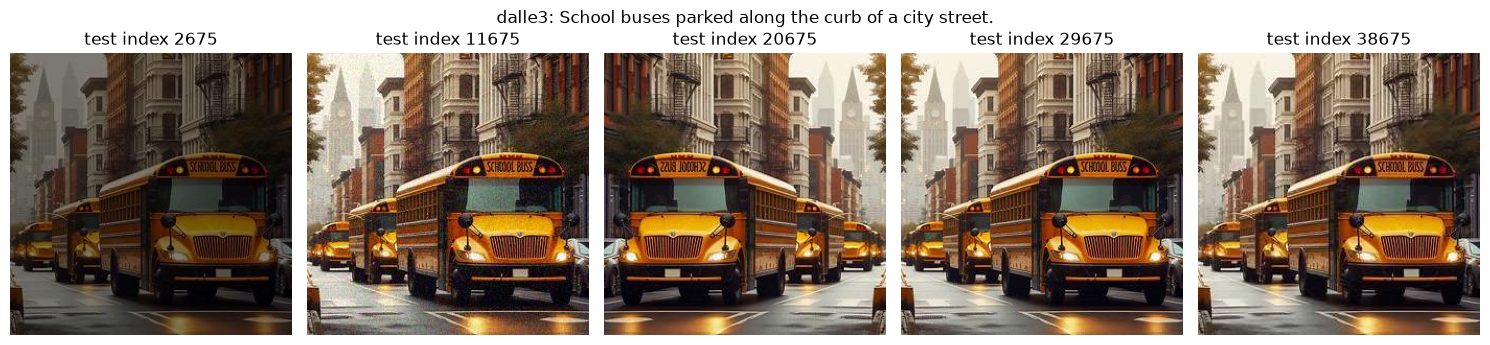

In [12]:
def find_indices(split_name, caption, label):
    split_captions = captions_per_split[split_name]
    split_labels = labels_per_split[split_name]
    indices = []
    for index in range(len(split_captions)):
        if split_captions[index] == caption and split_labels[index] == label:
            indices.append(index)
    return indices


test_caption = captions_per_split["test"][0]

for label in [0, 4]:
    indices = find_indices("test", test_caption, label)
    figure, axes = plt.subplots(1, len(indices), figsize=(15, 3.5))
    figure.suptitle(f"{SOURCE_NAMES[label]}: {test_caption}")
    for axis, index in zip(axes, indices):
        axis.imshow(dataset["test"][index]["Image"])
        axis.set_title(f"test index {index}")
        axis.axis("off")
    plt.tight_layout()
    plt.show()

## Example images

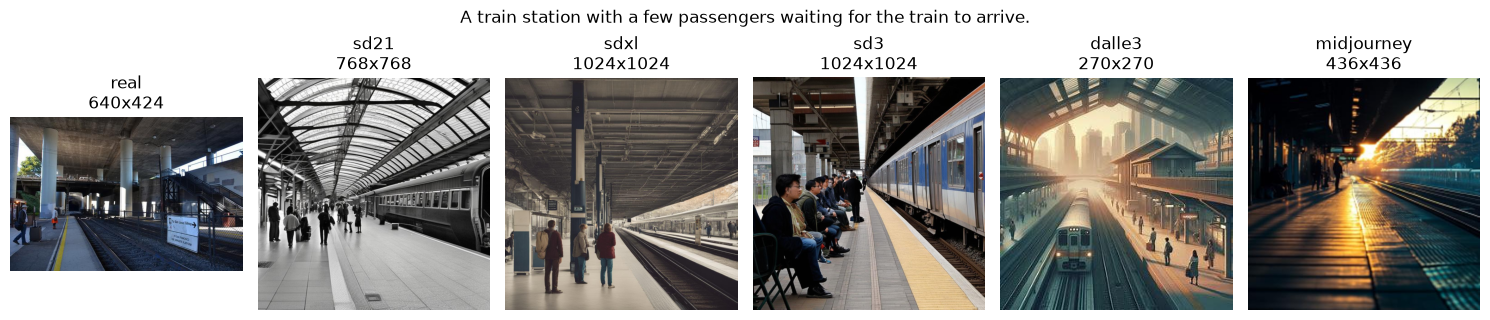

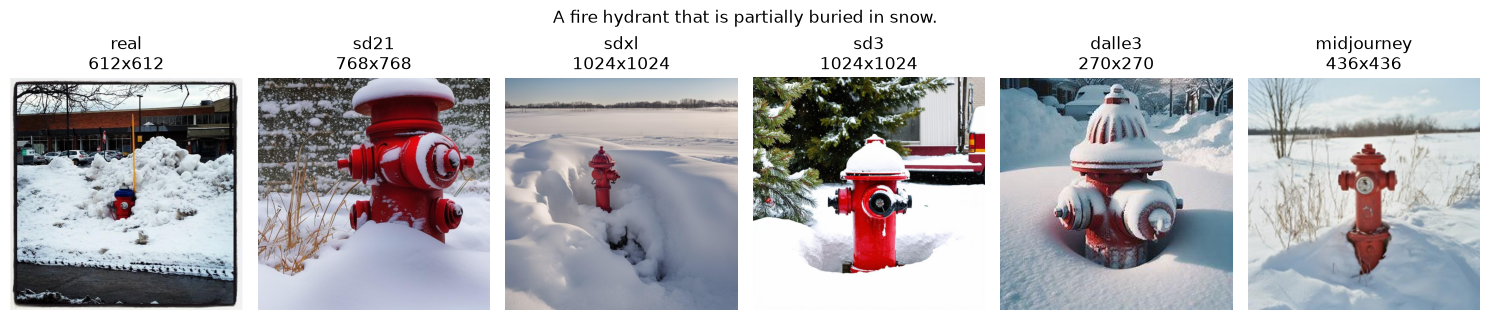

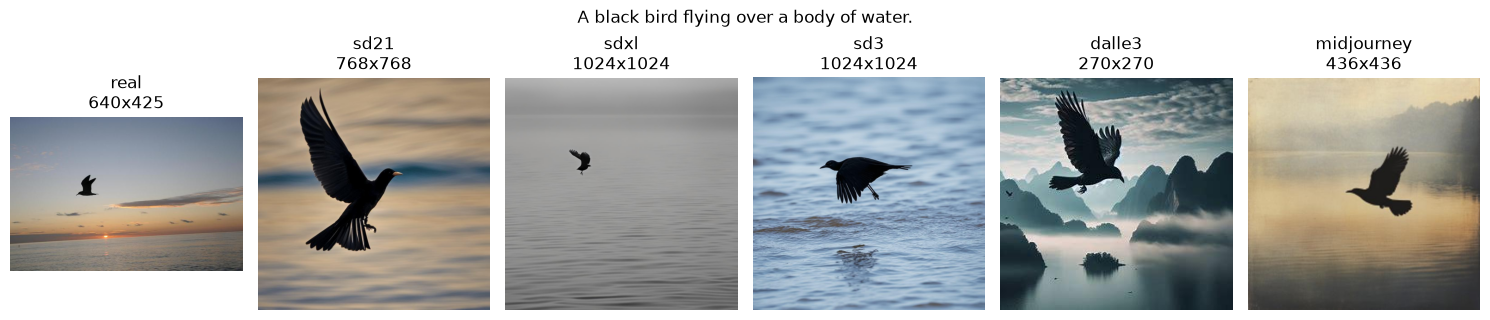

In [13]:
NUMBER_OF_EXAMPLES = 3

train_group_sizes = Counter(captions_per_split["train"])
complete_captions = []
for caption, number_of_images in train_group_sizes.items():
    if number_of_images == 6:
        complete_captions.append(caption)

for caption in random.sample(complete_captions, NUMBER_OF_EXAMPLES):
    figure, axes = plt.subplots(1, len(SOURCE_NAMES), figsize=(15, 3.5))
    figure.suptitle(caption)
    for label, source_name in enumerate(SOURCE_NAMES):
        index = find_indices("train", caption, label)[0]
        image = dataset["train"][index]["Image"]
        axes[label].imshow(image)
        axes[label].set_title(f"{source_name}\n{image.width}x{image.height}")
        axes[label].axis("off")
    plt.tight_layout()
    plt.show()